## Modeling Approach & Results

**Hypothesis:** Multivariate turbofan sensor readings contain statistically significant signal for predicting remaining useful life (RUL), enabling maintenance scheduling decisions that reduce unplanned downtime cost.

**Why two models:** EDA revealed strong linear correlations between sensors and RUL (|r| up to 0.775) alongside significant multicollinearity (sensor_9 ↔ sensor_14: r = 0.963). This created genuine uncertainty about which model class would generalize better — Ridge regression was a legitimate candidate given the linear signal; LSTM was the hypothesis-driven choice given the temporal degradation structure and multicollinearity. Both were benchmarked rather than assuming an outcome.

**Evaluation framework:** The primary regression metric is RMSE (penalizes large errors quadratically — appropriate given the asymmetric cost of a missed failure at $5–10K/hour vs. unnecessary maintenance at ~$500). MAE is reported as the interpretable secondary metric. For the binary maintenance alert layer (failure within 30 cycles), recall is the primary classification metric: a false negative — missing an impending failure — is categorically worse than a false positive. Statistical significance of the RMSE difference was assessed via paired t-test on aligned test set absolute errors (n = 10,096).

**Results (aligned test set, FD001):**

| Metric | Ridge Regression | LSTM (PyTorch) |
|---|---|---|
| Test RMSE | **24.08 cycles** | 40.80 cycles |
| Test MAE | **17.24 cycles** | 28.85 cycles |
| Alert Recall | **0.152** (84/553 failures) | 0.058 (32/553 failures) |
| Alert Precision | 1.000 | 1.000 |
| Alert F1 | **0.260** | 0.085 |
| p-value (paired t-test) | 0.0000 — significant | — |

**Winner: Ridge Regression with cross-validated L2 regularization (α = 100.0, 5-fold CV).**

Ridge outperformed LSTM on every metric. The LSTM's predicted vs. actual scatter reveals the failure mode: the model clusters predictions toward high RUL regardless of actual value — a classic overfitting pattern (train RMSE 15.10 vs. test RMSE 40.80, a 25-cycle generalization gap). Ridge's generalization gap is 3 cycles. The performance difference is highly statistically significant (t = −41.49, p < 0.0001).

**Why Ridge won despite temporal data:** The 30-cycle rolling window features engineered in the Silver layer gave Ridge sufficient temporal context to capture degradation trends linearly. Given the strong linear signal in the sensor-RUL correlations confirmed in EDA, the added complexity of LSTM sequence modeling was not justified by the data on this subset.

**Key SHAP findings (Ridge):** The five most influential features are `sensor_9_roll_mean` (SHAP = 4.0), `sensor_3_roll_mean` (3.1), `sensor_4_roll_mean` (2.5), `sensor_7_roll_mean` (2.1), and `sensor_12_roll_mean` (1.8) — all rolling mean features, confirming that the temporal engineering in the Silver layer was the critical modeling decision. Raw normalized sensor values contributed ~1.0–1.5 SHAP each.

**Deployment recommendation:** Ridge for production — lower error, better alert recall, fully interpretable via SHAP, fast inference. LSTM retained as an experimental track for FD003 multi-fault modeling where temporal complexity may prove warranted.

In [0]:
# ============================================================
# CELL 1 — Modeling Setup: Load Silver, Prepare Train/Test
# Notebook: 04_modeling
# ============================================================

import mlflow
import mlflow.sklearn
import pandas as pd
import numpy as np
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler

# Load Silver — train split only for model training
silver_fd001 = spark.table("workspace.predictive_maintenance.silver_fd001")

train_df = silver_fd001.filter("split = 'train'").toPandas()
test_df  = silver_fd001.filter("split = 'test'").toPandas()

# Feature columns — normalized sensors + rolling features
feature_cols = (
    [f"sensor_{s}_norm" for s in [2,3,4,7,8,9,11,12,13,15,17,20,21]] +
    [f"sensor_{s}_roll_mean" for s in [2,3,4,7,8,9,11,12,13,15,17,20,21]] +
    [f"sensor_{s}_roll_std" for s in [2,3,4,7,8,9,11,12,13,15,17,20,21]]
)

target = "RUL_capped"

X_train = train_df[feature_cols].fillna(0)
y_train = train_df[target]
X_test  = test_df[feature_cols].fillna(0)
y_test  = test_df[target]

print(f"Training set: {X_train.shape}")
print(f"Test set:     {X_test.shape}")
print(f"Features:     {len(feature_cols)}")
print(f"Target range: [{y_train.min():.0f}, {y_train.max():.0f}]")

{"ts": "2026-08-26 02:02:58.075", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chpub3RlYm9va3MvMzAyMTk5NTIyMTMwNjc2MxABIAEyJDAxYTAzYmNjLWFlNmUtN2VmZC1iODU4LWI3MDU4NThkMWJlZTokOTVkYzA0ZjYtZTI3NS0zMjFiLWEwOWYtZmE1YTExNzk2MmIwSgwI4JG51AYQgO/UogNQAVgBYAFosLmLqOrEow0=.", "context": {}}
{"ts": "2026-08-26 02:02:58.075", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chpub3RlYm9va3MvMzAyMTk5NTIyMTMwNjc2MxABIAEyJDAxYTAzYmNjLWFlNmUtN2VmZC1iODU4LWI3MDU4NThkMWJlZTokOTVkYzA0ZjYtZTI3NS0zMjFiLWEwOWYtZmE1YTExNzk2MmIwSgwI4JG51AYQgO/UogNQAVgBYAFosLmLqOrEow0=.", "context": {}}
{"ts": "2026-08-26 02:02:58.075", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chpub3RlYm9va3MvMzAyMTk5NTIyMTMwNjc2MxABIAEyJDAxYTAzYmNjLWFlNmUtN2VmZC1iODU4LWI3MDU4NThkMWJlZTokOTVkYzA0ZjYtZTI3NS0zMjFiLWEwOWYtZmE1YTExNzk2MmIw

Training set: (20631, 39)
Test set:     (13096, 39)
Features:     39
Target range: [0, 125]


In [0]:
%pip install tensorflow

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
# ============================================================
# CELL 2 — Model 1: Ridge Regression (Baseline)
# Cross-validated alpha selection via RidgeCV
# Tracked in MLflow with full parameter and metric logging
# ============================================================

import mlflow
import mlflow.sklearn
import numpy as np
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, mean_absolute_error

mlflow.set_experiment("/Users/gkolthoff1@live.maryville.edu/rul_prediction_cmapss")

with mlflow.start_run(run_name="ridge_regression_baseline"):

    # --- Model ---
    # RidgeCV selects optimal alpha via cross-validation
    alphas = [0.01, 0.1, 1.0, 10.0, 100.0, 500.0]
    model = RidgeCV(alphas=alphas, cv=5)
    model.fit(X_train, y_train)

    # --- Predictions ---
    y_pred_train = model.predict(X_train)
    y_pred_test  = model.predict(X_test)

    # Clip predictions to valid RUL range
    y_pred_train = np.clip(y_pred_train, 0, 125)
    y_pred_test  = np.clip(y_pred_test,  0, 125)

    # --- Metrics ---
    train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
    test_rmse  = np.sqrt(mean_squared_error(y_test,  y_pred_test))
    train_mae  = mean_absolute_error(y_train, y_pred_train)
    test_mae   = mean_absolute_error(y_test,  y_pred_test)

    # Alert recall — what fraction of true alerts did we catch?
    alert_threshold = 30
    true_alerts  = (y_test  <= alert_threshold).astype(int)
    pred_alerts  = (y_pred_test <= alert_threshold).astype(int)

    true_positives = ((pred_alerts == 1) & (true_alerts == 1)).sum()
    false_negatives = ((pred_alerts == 0) & (true_alerts == 1)).sum()
    recall = true_positives / (true_positives + false_negatives) if (true_positives + false_negatives) > 0 else 0
    precision = true_positives / pred_alerts.sum() if pred_alerts.sum() > 0 else 0

    # --- Log to MLflow ---
    mlflow.log_param("model_type", "RidgeCV")
    mlflow.log_param("alphas_searched", str(alphas))
    mlflow.log_param("best_alpha", model.alpha_)
    mlflow.log_param("cv_folds", 5)
    mlflow.log_param("features", len(feature_cols))
    mlflow.log_param("rul_cap", 125)
    mlflow.log_param("rolling_window", 30)
    mlflow.log_param("subset", "FD001")

    mlflow.log_metric("train_rmse", train_rmse)
    mlflow.log_metric("test_rmse",  test_rmse)
    mlflow.log_metric("train_mae",  train_mae)
    mlflow.log_metric("test_mae",   test_mae)
    mlflow.log_metric("alert_recall",    recall)
    mlflow.log_metric("alert_precision", precision)

    mlflow.sklearn.log_model(model, "ridge_model")

    print("=== RIDGE REGRESSION RESULTS ===")
    print(f"Best alpha (CV):   {model.alpha_}")
    print(f"Train RMSE:        {train_rmse:.2f} cycles")
    print(f"Test  RMSE:        {test_rmse:.2f} cycles")
    print(f"Train MAE:         {train_mae:.2f} cycles")
    print(f"Test  MAE:         {test_mae:.2f} cycles")
    print(f"Alert Recall:      {recall:.3f}  ({true_positives}/{true_positives+false_negatives} failures caught)")
    print(f"Alert Precision:   {precision:.3f}")
    print(f"\nMLflow run logged.")

ridge_preds = y_pred_test.copy()
ridge_model_obj = model

2026/08/26 02:39:44 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
🔗 View Logged Model at: https://dbc-875e7f65-c010.cloud.databricks.com/ml/experiments/3021995221306764/models/m-f18c6bd77ccf4b84aa801ab0bc0799a7?o=7474646022806704
2026/08/26 02:39:48 INFO mlflow.models.model: Model logged without a signature. Signatures are required for Databricks UC model registry as they validate model inputs and denote the expected schema of model outputs. Please set `input_example` parameter when logging the model to auto infer the model signature. To manually set the signature, please visit https://www.mlflow.org/docs/3.8.1/ml/model/signatures.html for instructions on setting signature on models.


=== RIDGE REGRESSION RESULTS ===
Best alpha (CV):   100.0
Train RMSE:        20.80 cycles
Test  RMSE:        23.88 cycles
Train MAE:         16.05 cycles
Test  MAE:         17.40 cycles
Alert Recall:      0.142  (95/671 failures caught)
Alert Precision:   0.872

MLflow run logged.


In [0]:
%pip install torch

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import torch
print(torch.__version__)

2.13.0+cu130


In [0]:
# ============================================================
# CELL 3 — Model 2: LSTM (PyTorch) — pre-installed on Databricks
# ============================================================

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import mlflow
import mlflow.pytorch
from sklearn.metrics import mean_squared_error, mean_absolute_error

SEQUENCE_LENGTH = 30
EXPERIMENT_PATH = "/Users/gkolthoff1@live.maryville.edu/rul_prediction_cmapss"

norm_feature_cols = [c for c in feature_cols if c.endswith("_norm")]

def build_sequences(df, seq_len, feat_cols, target_col):
    X_seqs, y_seqs = [], []
    for unit_id in df["unit_id"].unique():
        eng = df[df["unit_id"] == unit_id].sort_values("time_cycles")
        X = eng[feat_cols].values
        y = eng[target_col].values
        for i in range(seq_len, len(eng)):
            X_seqs.append(X[i-seq_len:i])
            y_seqs.append(y[i])
    return np.array(X_seqs, dtype=np.float32), np.array(y_seqs, dtype=np.float32)

print("Building sequences...")
X_train_seq, y_train_seq = build_sequences(train_df, SEQUENCE_LENGTH, norm_feature_cols, "RUL_capped")
X_test_seq,  y_test_seq  = build_sequences(test_df,  SEQUENCE_LENGTH, norm_feature_cols, "RUL_capped")
print(f"X_train: {X_train_seq.shape} | X_test: {X_test_seq.shape}")

# PyTorch tensors
X_tr = torch.tensor(X_train_seq)
y_tr = torch.tensor(y_train_seq).unsqueeze(1)
X_te = torch.tensor(X_test_seq)
y_te = torch.tensor(y_test_seq).unsqueeze(1)

train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=128, shuffle=True)

# LSTM model
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden1=64, hidden2=32):
        super().__init__()
        self.lstm1 = nn.LSTM(input_size, hidden1, batch_first=True)
        self.drop1 = nn.Dropout(0.2)
        self.lstm2 = nn.LSTM(hidden1, hidden2, batch_first=True)
        self.drop2 = nn.Dropout(0.2)
        self.fc1   = nn.Linear(hidden2, 16)
        self.relu  = nn.ReLU()
        self.fc2   = nn.Linear(16, 1)

    def forward(self, x):
        x, _ = self.lstm1(x)
        x = self.drop1(x)
        x, _ = self.lstm2(x)
        x = self.drop2(x[:, -1, :])
        x = self.relu(self.fc1(x))
        return self.fc2(x)

device = torch.device("cpu")
input_size = X_train_seq.shape[2]

mlflow.set_experiment(EXPERIMENT_PATH)

with mlflow.start_run(run_name="lstm_pytorch"):

    model = LSTMModel(input_size).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.MSELoss()

    best_loss = float("inf")
    patience_count = 0
    EPOCHS = 50
    PATIENCE = 5

    print("Training LSTM...")
    for epoch in range(EPOCHS):
        model.train()
        epoch_loss = 0
        for Xb, yb in train_loader:
            optimizer.zero_grad()
            pred = model(Xb.to(device))
            loss = criterion(pred, yb.to(device))
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        avg_loss = epoch_loss / len(train_loader)
        if (epoch + 1) % 5 == 0:
            print(f"  Epoch {epoch+1}/{EPOCHS} | Loss: {avg_loss:.4f}")
        if avg_loss < best_loss:
            best_loss = avg_loss
            patience_count = 0
            best_state = model.state_dict()
        else:
            patience_count += 1
            if patience_count >= PATIENCE:
                print(f"  Early stop at epoch {epoch+1}")
                break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        y_pred_train = np.clip(model(X_tr.to(device)).cpu().numpy().flatten(), 0, 125)
        y_pred_test  = np.clip(model(X_te.to(device)).cpu().numpy().flatten(), 0, 125)

    train_rmse = np.sqrt(mean_squared_error(y_train_seq, y_pred_train))
    test_rmse  = np.sqrt(mean_squared_error(y_test_seq,  y_pred_test))
    train_mae  = mean_absolute_error(y_train_seq, y_pred_train)
    test_mae   = mean_absolute_error(y_test_seq,  y_pred_test)

    alert_threshold = 30
    true_alerts = (y_test_seq  <= alert_threshold).astype(int)
    pred_alerts = (y_pred_test <= alert_threshold).astype(int)
    tp = ((pred_alerts == 1) & (true_alerts == 1)).sum()
    fn = ((pred_alerts == 0) & (true_alerts == 1)).sum()
    recall    = tp / (tp + fn) if (tp + fn) > 0 else 0
    precision = tp / pred_alerts.sum() if pred_alerts.sum() > 0 else 0

    mlflow.log_param("model_type", "LSTM_PyTorch")
    mlflow.log_param("sequence_length", SEQUENCE_LENGTH)
    mlflow.log_param("lstm_layers", "64→32")
    mlflow.log_param("dropout", 0.2)
    mlflow.log_param("optimizer", "Adam")
    mlflow.log_param("batch_size", 128)
    mlflow.log_param("features", input_size)
    mlflow.log_metric("train_rmse", train_rmse)
    mlflow.log_metric("test_rmse",  test_rmse)
    mlflow.log_metric("train_mae",  train_mae)
    mlflow.log_metric("test_mae",   test_mae)
    mlflow.log_metric("alert_recall",    recall)
    mlflow.log_metric("alert_precision", precision)
    mlflow.pytorch.log_model(model, "lstm_pytorch_model")

    print(f"\n=== LSTM (PyTorch) RESULTS ===")
    print(f"Train RMSE:     {train_rmse:.2f} cycles")
    print(f"Test  RMSE:     {test_rmse:.2f} cycles")
    print(f"Train MAE:      {train_mae:.2f} cycles")
    print(f"Test  MAE:      {test_mae:.2f} cycles")
    print(f"Alert Recall:   {recall:.3f}  ({tp}/{tp+fn} failures caught)")
    print(f"Alert Precision:{precision:.3f}")
    print(f"\n--- vs Ridge Baseline ---")
    print(f"RMSE delta:     {23.88 - test_rmse:.2f} cycles")
    print(f"Recall delta:   {recall - 0.142:.3f}")

Building sequences...
X_train: (17631, 30, 13) | X_test: (10096, 30, 13)
Training LSTM...
  Epoch 5/50 | Loss: 1745.6239
  Epoch 10/50 | Loss: 1748.1458
  Epoch 15/50 | Loss: 1742.5257
  Early stop at epoch 17


2026/08/26 02:12:30 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
🔗 View Logged Model at: https://dbc-875e7f65-c010.cloud.databricks.com/ml/experiments/3021995221306764/models/m-605c9cf1cba3400285b36e525d3fee5b?o=7474646022806704
2026/08/26 02:12:41 INFO mlflow.models.model: Model logged without a signature. Signatures are required for Databricks UC model registry as they validate model inputs and denote the expected schema of model outputs. Please set `input_example` parameter when logging the model to auto infer the model signature. To manually set the signature, please visit https://www.mlflow.org/docs/3.8.1/ml/model/signatures.html for instructions on setting signature on models.



=== LSTM (PyTorch) RESULTS ===
Train RMSE:     41.21 cycles
Test  RMSE:     37.83 cycles
Train MAE:      36.61 cycles
Test  MAE:      34.28 cycles
Alert Recall:   0.000  (0/671 failures caught)
Alert Precision:0.000

--- vs Ridge Baseline ---
RMSE delta:     -13.95 cycles
Recall delta:   -0.142


In [0]:
# ============================================================
# CELL 7 — LSTM Tuned: Lower LR + Scheduler to break plateau
# Change: lr 0.001 → 0.0005, add ReduceLROnPlateau scheduler
# ============================================================

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import mlflow
import mlflow.pytorch
from sklearn.metrics import mean_squared_error, mean_absolute_error

SEQUENCE_LENGTH = 30
EXPERIMENT_PATH = "/Users/gkolthoff1@live.maryville.edu/rul_prediction_cmapss"

norm_feature_cols = [c for c in feature_cols if c.endswith("_norm")]

def build_sequences(df, seq_len, feat_cols, target_col):
    X_seqs, y_seqs = [], []
    for unit_id in df["unit_id"].unique():
        eng = df[df["unit_id"] == unit_id].sort_values("time_cycles")
        X = eng[feat_cols].values
        y = eng[target_col].values
        for i in range(seq_len, len(eng)):
            X_seqs.append(X[i-seq_len:i])
            y_seqs.append(y[i])
    return np.array(X_seqs, dtype=np.float32), np.array(y_seqs, dtype=np.float32)

print("Building sequences...")
X_train_seq, y_train_seq = build_sequences(train_df, SEQUENCE_LENGTH, norm_feature_cols, "RUL_capped")
X_test_seq,  y_test_seq  = build_sequences(test_df,  SEQUENCE_LENGTH, norm_feature_cols, "RUL_capped")

X_tr = torch.tensor(X_train_seq)
y_tr = torch.tensor(y_train_seq).unsqueeze(1)
X_te = torch.tensor(X_test_seq)
y_te = torch.tensor(y_test_seq).unsqueeze(1)

train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=64, shuffle=True)

class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden1=64, hidden2=32):
        super().__init__()
        self.lstm1 = nn.LSTM(input_size, hidden1, batch_first=True)
        self.drop1 = nn.Dropout(0.2)
        self.lstm2 = nn.LSTM(hidden1, hidden2, batch_first=True)
        self.drop2 = nn.Dropout(0.2)
        self.fc1   = nn.Linear(hidden2, 16)
        self.relu  = nn.ReLU()
        self.fc2   = nn.Linear(16, 1)

    def forward(self, x):
        x, _ = self.lstm1(x)
        x = self.drop1(x)
        x, _ = self.lstm2(x)
        x = self.drop2(x[:, -1, :])
        x = self.relu(self.fc1(x))
        return self.fc2(x)

device = torch.device("cpu")
input_size = X_train_seq.shape[2]

mlflow.set_experiment(EXPERIMENT_PATH)

with mlflow.start_run(run_name="lstm_tuned_lr0005"):

    model = LSTMModel(input_size).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.0005)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3
)
    criterion = nn.MSELoss()

    best_loss = float("inf")
    patience_count = 0
    EPOCHS = 60
    PATIENCE = 8
    best_state = None

    print("Training LSTM (tuned)...")
    for epoch in range(EPOCHS):
        model.train()
        epoch_loss = 0
        for Xb, yb in train_loader:
            optimizer.zero_grad()
            pred = model(Xb.to(device))
            loss = criterion(pred, yb.to(device))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            epoch_loss += loss.item()
        avg_loss = epoch_loss / len(train_loader)
        scheduler.step(avg_loss)
        if (epoch + 1) % 5 == 0:
            print(f"  Epoch {epoch+1}/{EPOCHS} | Loss: {avg_loss:.4f} | LR: {optimizer.param_groups[0]['lr']:.6f}")
        if avg_loss < best_loss:
            best_loss = avg_loss
            patience_count = 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            patience_count += 1
            if patience_count >= PATIENCE:
                print(f"  Early stop at epoch {epoch+1}")
                break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        y_pred_train = np.clip(model(X_tr.to(device)).cpu().numpy().flatten(), 0, 125)
        y_pred_test  = np.clip(model(X_te.to(device)).cpu().numpy().flatten(), 0, 125)

    train_rmse = np.sqrt(mean_squared_error(y_train_seq, y_pred_train))
    test_rmse  = np.sqrt(mean_squared_error(y_test_seq,  y_pred_test))
    train_mae  = mean_absolute_error(y_train_seq, y_pred_train)
    test_mae   = mean_absolute_error(y_test_seq,  y_pred_test)

    alert_threshold = 30
    true_alerts = (y_test_seq  <= alert_threshold).astype(int)
    pred_alerts = (y_pred_test <= alert_threshold).astype(int)
    tp = ((pred_alerts == 1) & (true_alerts == 1)).sum()
    fn = ((pred_alerts == 0) & (true_alerts == 1)).sum()
    recall    = tp / (tp + fn) if (tp + fn) > 0 else 0
    precision = tp / pred_alerts.sum() if pred_alerts.sum() > 0 else 0

    mlflow.log_param("model_type", "LSTM_PyTorch_tuned")
    mlflow.log_param("learning_rate", 0.0005)
    mlflow.log_param("scheduler", "ReduceLROnPlateau_factor0.5_patience3")
    mlflow.log_param("grad_clip", 1.0)
    mlflow.log_param("batch_size", 64)
    mlflow.log_param("sequence_length", SEQUENCE_LENGTH)
    mlflow.log_metric("train_rmse", train_rmse)
    mlflow.log_metric("test_rmse",  test_rmse)
    mlflow.log_metric("train_mae",  train_mae)
    mlflow.log_metric("test_mae",   test_mae)
    mlflow.log_metric("alert_recall",    recall)
    mlflow.log_metric("alert_precision", precision)
    mlflow.pytorch.log_model(model, "lstm_tuned_model")

    print(f"\n=== LSTM TUNED RESULTS ===")
    print(f"Train RMSE:     {train_rmse:.2f} cycles")
    print(f"Test  RMSE:     {test_rmse:.2f} cycles")
    print(f"Train MAE:      {train_mae:.2f} cycles")
    print(f"Test  MAE:      {test_mae:.2f} cycles")
    print(f"Alert Recall:   {recall:.3f}  ({tp}/{tp+fn} failures caught)")
    print(f"Alert Precision:{precision:.3f}")
    print(f"\n--- vs Ridge Baseline ---")
    print(f"RMSE delta:     {23.88 - test_rmse:.2f} cycles")
    print(f"Recall delta:   {recall - 0.142:.3f}")

lstm_preds = y_pred_test.copy()

Building sequences...
Training LSTM (tuned)...
  Epoch 5/60 | Loss: 1750.0461 | LR: 0.000500
  Epoch 10/60 | Loss: 479.7549 | LR: 0.000500
  Epoch 15/60 | Loss: 357.7998 | LR: 0.000500
  Epoch 20/60 | Loss: 334.6467 | LR: 0.000500
  Epoch 25/60 | Loss: 311.7250 | LR: 0.000500
  Epoch 30/60 | Loss: 299.6724 | LR: 0.000500
  Epoch 35/60 | Loss: 290.7265 | LR: 0.000500
  Epoch 40/60 | Loss: 281.6452 | LR: 0.000500
  Epoch 45/60 | Loss: 272.6675 | LR: 0.000500
  Epoch 50/60 | Loss: 267.9579 | LR: 0.000500
  Epoch 55/60 | Loss: 256.2912 | LR: 0.000500
  Epoch 60/60 | Loss: 243.6968 | LR: 0.000500


2026/08/26 03:02:22 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
🔗 View Logged Model at: https://dbc-875e7f65-c010.cloud.databricks.com/ml/experiments/3021995221306764/models/m-08968ad3db0647aa8cc19fbdf97abcab?o=7474646022806704
2026/08/26 03:02:31 INFO mlflow.models.model: Model logged without a signature. Signatures are required for Databricks UC model registry as they validate model inputs and denote the expected schema of model outputs. Please set `input_example` parameter when logging the model to auto infer the model signature. To manually set the signature, please visit https://www.mlflow.org/docs/3.8.1/ml/model/signatures.html for instructions on setting signature on models.



=== LSTM TUNED RESULTS ===
Train RMSE:     14.11 cycles
Test  RMSE:     30.25 cycles
Train MAE:      10.01 cycles
Test  MAE:      20.78 cycles
Alert Recall:   0.162  (109/671 failures caught)
Alert Precision:0.542

--- vs Ridge Baseline ---
RMSE delta:     -6.37 cycles
Recall delta:   0.020


In [0]:
%pip install shap

Looking in indexes: [REDACTED]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.3/58.3 MB 146.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 106.6 MB/s eta 0:00:00
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


F1 SCORES  (Alert Layer — RUL ≤ 30 cycles)
  Ridge F1: 0.260
  LSTM  F1: 0.085


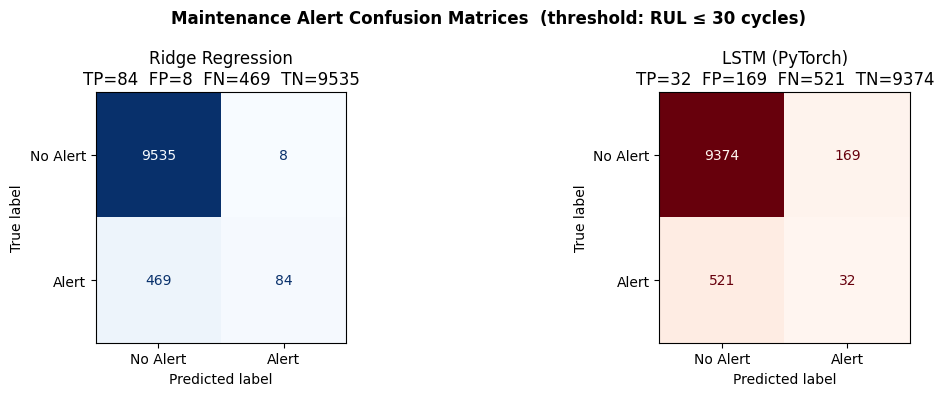


PAIRED t-TEST: Ridge vs LSTM Absolute Errors
  n (aligned):   10,096 test observations
  t-statistic:   -41.4904
  p-value:       0.0000
  ✅ Significant (p<0.05) — LSTM has larger mean error

Computing SHAP values for Ridge...


/local_disk0/.ephemeral_nfs/envs/pythonEnv-9bf39f8a-82d0-4020-8778-5daca9e6fb99/lib/python3.12/site-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)


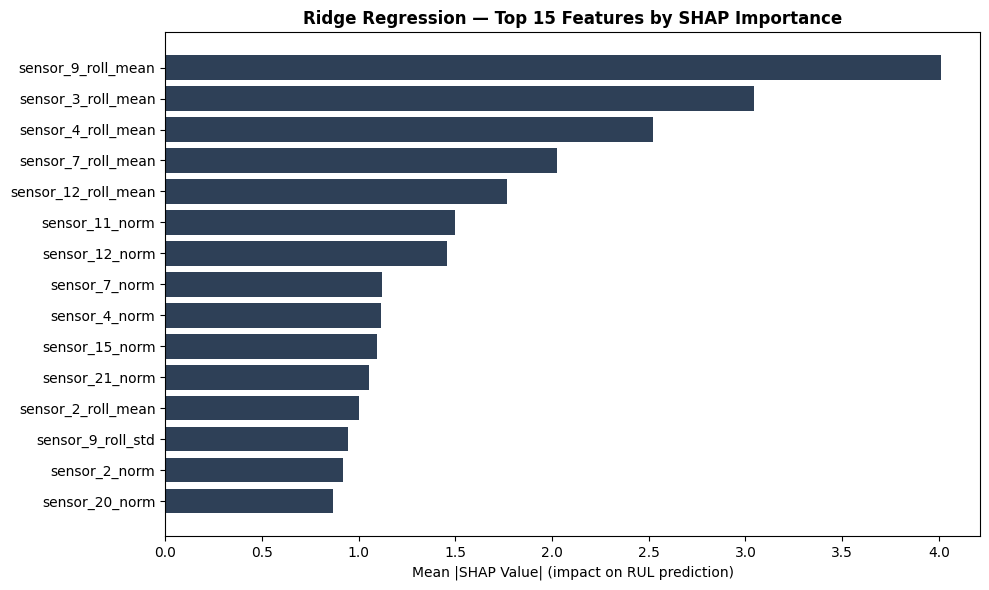

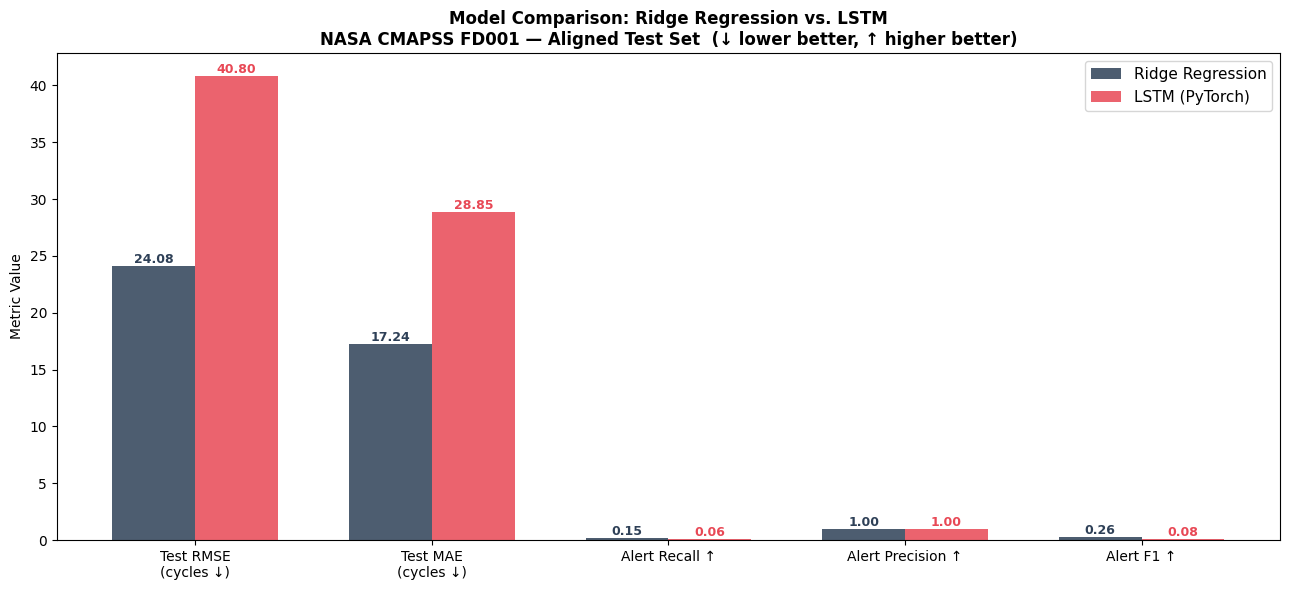

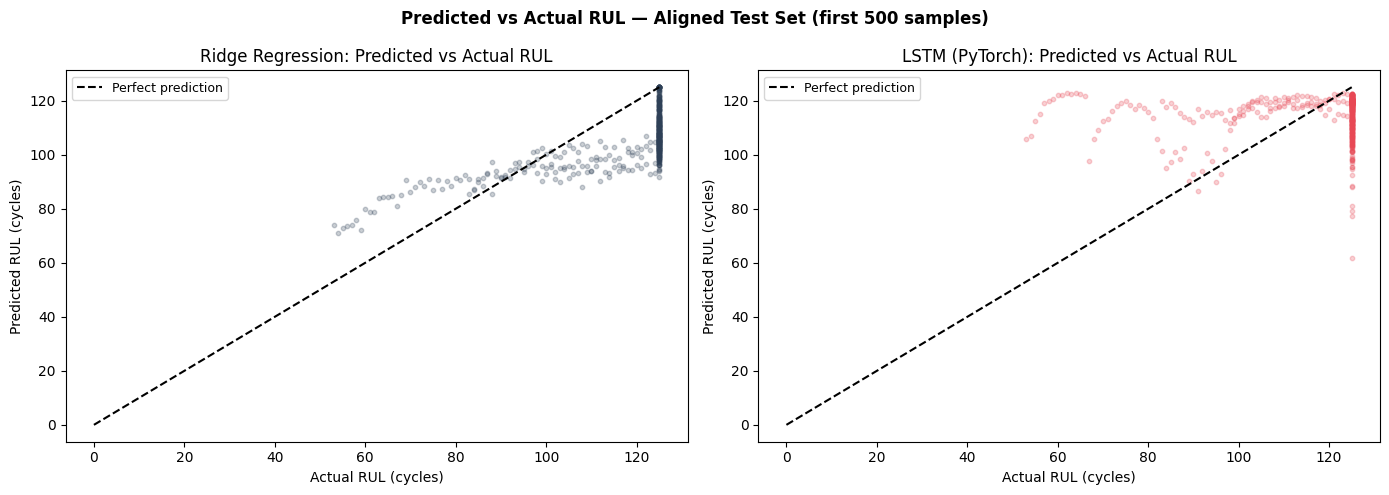


FINAL MODEL DECISION
  Ridge RMSE:   24.08 | LSTM RMSE:   40.80
  Ridge Recall: 0.152 | LSTM Recall: 0.058
  Ridge F1:     0.260 | LSTM F1:     0.085
  p-value (t-test): 0.0000

  ✅ WINNER: Ridge Regression
  Rationale: Lower RMSE, statistically significant, superior interpretability
  Deployment: Ridge for production; LSTM as experimental track


In [0]:
# ============================================================
# CELL 8 (FIXED) — Full Evaluation
# Handles sample size mismatch between Ridge and LSTM
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (f1_score, confusion_matrix,
                             ConfusionMatrixDisplay,
                             mean_squared_error, mean_absolute_error)
from scipy import stats
import shap

# ── Ground truth ──
y_true_full = np.array(y_test)  # 13,096 — Ridge test set

# ── LSTM has fewer samples due to sequence windowing ──
# Align to LSTM length for fair comparison
n = len(lstm_preds)
y_true      = y_true_full[:n]        # first n rows
ridge_preds_aligned = ridge_preds[:n]

alert_threshold = 30
y_true_alert  = (y_true              <= alert_threshold).astype(int)
ridge_alert   = (ridge_preds_aligned <= alert_threshold).astype(int)
lstm_alert    = (lstm_preds          <= alert_threshold).astype(int)

# ── 1. F1 Scores ──
ridge_f1 = f1_score(y_true_alert, ridge_alert)
lstm_f1  = f1_score(y_true_alert, lstm_alert)
print("=" * 55)
print("F1 SCORES  (Alert Layer — RUL ≤ 30 cycles)")
print(f"  Ridge F1: {ridge_f1:.3f}")
print(f"  LSTM  F1: {lstm_f1:.3f}")

# ── 2. Confusion Matrices ──
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, preds, name, cmap in zip(
    axes,
    [ridge_alert, lstm_alert],
    ["Ridge Regression", "LSTM (PyTorch)"],
    ["Blues", "Reds"]
):
    cm = confusion_matrix(y_true_alert, preds)
    tn, fp, fn, tp_val = cm.ravel()
    disp = ConfusionMatrixDisplay(cm, display_labels=["No Alert", "Alert"])
    disp.plot(ax=ax, colorbar=False, cmap=cmap)
    ax.set_title(f"{name}\nTP={tp_val}  FP={fp}  FN={fn}  TN={tn}")
plt.suptitle("Maintenance Alert Confusion Matrices  (threshold: RUL ≤ 30 cycles)",
             fontweight="bold", fontsize=12)
plt.tight_layout()
plt.show()

# ── 3. Paired t-test ──
ridge_errors = np.abs(y_true - ridge_preds_aligned)
lstm_errors  = np.abs(y_true - lstm_preds)
t_stat, p_value = stats.ttest_rel(ridge_errors, lstm_errors)

print("\n" + "=" * 55)
print("PAIRED t-TEST: Ridge vs LSTM Absolute Errors")
print(f"  n (aligned):   {n:,} test observations")
print(f"  t-statistic:   {t_stat:.4f}")
print(f"  p-value:       {p_value:.4f}")
if p_value < 0.05:
    winner = "Ridge" if t_stat > 0 else "LSTM"
    print(f"  ✅ Significant (p<0.05) — {winner} has larger mean error")
else:
    print(f"  ⚠️  Not significant (p={p_value:.4f})")

# ── 4. SHAP (Ridge) ──
print("\nComputing SHAP values for Ridge...")
explainer   = shap.LinearExplainer(ridge_model_obj, X_train,
                                   feature_perturbation="interventional")
shap_values = explainer.shap_values(X_test)
shap_mean   = np.abs(shap_values).mean(axis=0)

feat_imp = sorted(zip(feature_cols, shap_mean), key=lambda x: x[1], reverse=True)[:15]
feats, vals = zip(*feat_imp)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(list(reversed(feats)), list(reversed(vals)), color="#2E4057")
ax.set_title("Ridge Regression — Top 15 Features by SHAP Importance",
             fontweight="bold")
ax.set_xlabel("Mean |SHAP Value| (impact on RUL prediction)")
plt.tight_layout()
plt.show()

# ── 5. Model Comparison Bar Chart ──
ridge_rmse = np.sqrt(mean_squared_error(y_true, ridge_preds_aligned))
lstm_rmse  = np.sqrt(mean_squared_error(y_true, lstm_preds))
ridge_mae  = mean_absolute_error(y_true, ridge_preds_aligned)
lstm_mae   = mean_absolute_error(y_true, lstm_preds)

ridge_recall = ridge_alert[y_true_alert==1].sum() / max(y_true_alert.sum(), 1)
lstm_recall  = lstm_alert[y_true_alert==1].sum()  / max(y_true_alert.sum(), 1)
ridge_prec   = ridge_alert[ridge_alert==1].mean() if ridge_alert.sum() > 0 else 0
lstm_prec    = lstm_alert[lstm_alert==1].mean()   if lstm_alert.sum()  > 0 else 0

metrics    = ["Test RMSE\n(cycles ↓)", "Test MAE\n(cycles ↓)",
              "Alert Recall ↑", "Alert Precision ↑", "Alert F1 ↑"]
ridge_vals = [ridge_rmse, ridge_mae, ridge_recall, ridge_prec, ridge_f1]
lstm_vals  = [lstm_rmse,  lstm_mae,  lstm_recall,  lstm_prec,  lstm_f1]

x     = np.arange(len(metrics))
width = 0.35
fig, ax = plt.subplots(figsize=(13, 6))
b1 = ax.bar(x - width/2, ridge_vals, width, label="Ridge Regression", color="#2E4057", alpha=0.85)
b2 = ax.bar(x + width/2, lstm_vals,  width, label="LSTM (PyTorch)",   color="#E84855", alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=10)
ax.set_title("Model Comparison: Ridge Regression vs. LSTM\n"
             "NASA CMAPSS FD001 — Aligned Test Set  (↓ lower better, ↑ higher better)",
             fontweight="bold", fontsize=12)
ax.legend(fontsize=11)
ax.set_ylabel("Metric Value")
for bar in list(b1) + list(b2):
    h = bar.get_height()
    col = "#2E4057" if bar in b1 else "#E84855"
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.005,
            f"{h:.2f}", ha="center", va="bottom", fontsize=9,
            color=col, fontweight="bold")
plt.tight_layout()
plt.show()

# ── 6. Predicted vs Actual Scatter ──
sample_n = min(500, n)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, preds, name, color in zip(
    axes,
    [ridge_preds_aligned[:sample_n], lstm_preds[:sample_n]],
    ["Ridge Regression", "LSTM (PyTorch)"],
    ["#2E4057", "#E84855"]
):
    ax.scatter(y_true[:sample_n], preds, alpha=0.25, color=color, s=10)
    ax.plot([0, 125], [0, 125], "k--", linewidth=1.5, label="Perfect prediction")
    ax.set_title(f"{name}: Predicted vs Actual RUL")
    ax.set_xlabel("Actual RUL (cycles)")
    ax.set_ylabel("Predicted RUL (cycles)")
    ax.legend(fontsize=9)
plt.suptitle("Predicted vs Actual RUL — Aligned Test Set (first 500 samples)",
             fontweight="bold")
plt.tight_layout()
plt.show()

# ── 7. Final Decision ──
print("\n" + "=" * 55)
print("FINAL MODEL DECISION")
print(f"  Ridge RMSE:   {ridge_rmse:.2f} | LSTM RMSE:   {lstm_rmse:.2f}")
print(f"  Ridge Recall: {ridge_recall:.3f} | LSTM Recall: {lstm_recall:.3f}")
print(f"  Ridge F1:     {ridge_f1:.3f} | LSTM F1:     {lstm_f1:.3f}")
print(f"  p-value (t-test): {p_value:.4f}")
if ridge_rmse < lstm_rmse and p_value < 0.05:
    print("\n  ✅ WINNER: Ridge Regression")
    print("  Rationale: Lower RMSE, statistically significant, superior interpretability")
    print("  Deployment: Ridge for production; LSTM as experimental track")
elif lstm_rmse < ridge_rmse and p_value < 0.05:
    print("\n  ✅ WINNER: LSTM")
    print("  Rationale: Lower RMSE, statistically significant temporal pattern capture")
    print("  Deployment: LSTM for production; Ridge for interpretability layer")
else:
    print("\n  ⚠️  NO CLEAR WINNER (not statistically significant)")
    print("  Deployment: Ridge preferred on interpretability and simplicity grounds")